# Olist — Data Profiling de `olist_orders_dataset.csv`

Análise exploratória da tabela de pedidos do dataset público de e-commerce da Olist, usando
**profiling automatizado** com o `fg-data-profiling` (sucessor do `ydata-profiling`).

O profiling cobre a parte mecânica da EDA: tipos, cardinalidade, distribuições, nulos,
duplicatas, correlações e alertas de qualidade. O que ele não faz é entender o domínio:
as datas só viram informação quando viram **diferenças** (tempo de entrega, atraso, folga).
Por isso o notebook também cria features de tempo, compara pedidos no prazo e atrasados,
checa a ordem lógica das datas e olha a série mensal.

Relatórios gerados em `reports/`:

| Arquivo | Conteúdo |
|---|---|
| `olist_orders_profiling.html` | perfil da tabela bruta |
| `olist_orders_profiling_enriquecido.html` | perfil com as features de tempo |
| `olist_orders_profiling_comparativo.html` | pedidos no prazo × atrasados lado a lado |

## 0. Ambiente

O pacote atual é o `fg-data-profiling` e o import é `data_profiling`. Ele já está no
`pyproject.toml` do projeto, junto com `setuptools<81` (a biblioteca ainda usa `pkg_resources`).

In [1]:
%matplotlib inline

import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from data_profiling import ProfileReport, compare

# Avisos internos da biblioteca de profiling, não do nosso código.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.SettingWithCopyWarning)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

## 1. Carregamento

As cinco colunas de data são convertidas para `datetime` já na leitura. Se chegarem como
texto, o profiling as trata como categorias de altíssima cardinalidade e a análise temporal
do relatório se perde.

In [2]:
# Sobe a partir da pasta atual até achar data/raw (funciona rodando de notebooks/ ou da raiz).
def encontrar_raiz(inicio: Path | None = None) -> Path:
    inicio = inicio or Path.cwd()
    for pasta in [inicio, *inicio.parents]:
        if (pasta / "data" / "raw").exists():
            return pasta
    raise FileNotFoundError(f"Pasta data/raw não encontrada a partir de {inicio}")


PROJ_ROOT = encontrar_raiz()
CSV_PATH = PROJ_ROOT / "data" / "raw" / "olist_orders_dataset.csv"
REPORTS_DIR = PROJ_ROOT / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

COLS_DATA = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = pd.read_csv(CSV_PATH, parse_dates=COLS_DATA)

print(f"Arquivo : {CSV_PATH.relative_to(PROJ_ROOT)}")
print(f"Formato : {orders.shape[0]} linhas x {orders.shape[1]} colunas")
print(f"Memória : {orders.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
orders.head()

Arquivo : data\raw\olist_orders_dataset.csv
Formato : 99441 linhas x 8 colunas
Memória : 24.7 MB


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


## 2. Perfil bruto

Dois ajustes deixam o relatório mais rápido e mais útil neste dataset:

- **`vars.cat.words/characters = False`**: `order_id` e `customer_id` têm ~99 mil valores
  únicos. Analisar palavras e caracteres de hashes é caro e não informa nada.
- **`interactions.continuous = False`**: os gráficos de dispersão cruzariam todo par de
  colunas numéricas com 99 mil pontos cada.

As descrições das colunas e os metadados do dataset ficam embutidos no próprio HTML.

In [3]:
DESCRICOES = {
    "order_id": "Identificador único do pedido (chave primária).",
    "customer_id": "Chave do cliente PARA ESTE PEDIDO — não identifica a pessoa.",
    "order_status": "Estado do pedido no ciclo de vida (delivered, shipped, canceled, ...).",
    "order_purchase_timestamp": "Momento da compra.",
    "order_approved_at": "Momento da aprovação do pagamento.",
    "order_delivered_carrier_date": "Postagem: entrega do pedido à transportadora.",
    "order_delivered_customer_date": "Entrega efetiva ao cliente.",
    "order_estimated_delivery_date": "Prazo prometido ao cliente no momento da compra.",
}

METADADOS = {
    "description": (
        "Tabela de pedidos do Brazilian E-Commerce Public Dataset by Olist. "
        "Uma linha por pedido, com o ciclo de vida completo em timestamps."
    ),
    "url": "https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce",
    "copyright_holder": "Olist",
    "creator": "Olist Store",
}

# Configuração comum aos relatórios deste notebook.
CONFIG_BASE = dict(
    explorative=True,
    vars={"cat": {"words": False, "characters": False}},
    interactions={"continuous": False},
    correlations={"auto": {"calculate": True}},
    missing_diagrams={"bar": True, "matrix": True, "heatmap": True},
    samples={"head": 10, "tail": 10},
    progress_bar=False,
)

In [4]:
HTML_BRUTO = REPORTS_DIR / "olist_orders_profiling.html"

t0 = time.perf_counter()
perfil_bruto = ProfileReport(
    orders,
    title="Olist — Pedidos (dados brutos)",
    dataset=METADADOS,
    variables={"descriptions": DESCRICOES},
    type_schema={"order_status": "categorical"},
    **CONFIG_BASE,
)
perfil_bruto.to_file(HTML_BRUTO)

print(f"Relatório salvo em: {HTML_BRUTO.relative_to(PROJ_ROOT)}")
print(f"Tamanho          : {HTML_BRUTO.stat().st_size / 1024**2:.1f} MB")
print(f"Tempo            : {time.perf_counter() - t0:.1f}s")

  0%|          | 0/8 [00:00<?, ?it/s]

 12%|█▎        | 1/8 [00:01<00:09,  1.34s/it]

100%|██████████| 8/8 [00:01<00:00,  5.97it/s]

Relatório salvo em: reports\olist_orders_profiling.html
Tamanho          : 1.6 MB
Tempo            : 5.0s


In [5]:
# O relatório embutido deixa o .ipynb com vários MB. Ligue só para explorar;
# o HTML salvo em reports/ pode ser aberto direto no navegador.
MOSTRAR_INLINE = False

if MOSTRAR_INLINE:
    perfil_bruto.to_notebook_iframe()

## 3. Alertas e estatísticas extraídos do relatório

O HTML é para leitura humana. Para automação (testes de qualidade, comparação entre versões
do dado) usamos o `get_description()`, que expõe tudo como objetos Python.

In [6]:
descricao = perfil_bruto.get_description()

alertas = pd.DataFrame(
    [
        {
            "coluna": getattr(alerta, "column_name", None) or "—",
            "tipo": str(getattr(alerta, "alert_type", "")).split(".")[-1],
            "detalhe": str(alerta),
        }
        for alerta in descricao.alerts
    ]
)

print(f"{len(alertas)} alertas de qualidade levantados automaticamente")
alertas

5 alertas de qualidade levantados automaticamente


,coluna,tipo,detalhe
0,order_status,IMBALANCE,[order_status] is highly imbalanced (0.9139469...
1,order_delivered_carrier_date,MISSING,[order_delivered_carrier_date] 1783 (1.8%) mis...
2,order_delivered_customer_date,MISSING,[order_delivered_customer_date] 2965 (3.0%) mi...
3,order_id,UNIQUE,[order_id] has unique values
4,customer_id,UNIQUE,[customer_id] has unique values


In [7]:
tabela = descricao.table

print(f"Linhas                 : {tabela['n']}")
print(f"Colunas                : {tabela['n_var']}")
print(f"Células ausentes       : {tabela['n_cells_missing']} ({tabela['p_cells_missing'] * 100:.2f}%)")
print(f"Colunas com algum nulo : {tabela['n_vars_with_missing']}")
print(f"Linhas duplicadas      : {tabela['n_duplicates']}")

# Resumo por coluna, direto do objeto de descrição.
pd.DataFrame(
    {
        coluna: {
            "tipo": stats.get("type"),
            "distintos": stats.get("n_distinct"),
            "pct_distintos": round(stats.get("p_distinct", 0) * 100, 2),
            "nulos": stats.get("n_missing"),
            "pct_nulos": round(stats.get("p_missing", 0) * 100, 2),
        }
        for coluna, stats in descricao.variables.items()
    }
).T

Linhas                 : 99441
Colunas                : 8
Células ausentes       : 4908 (0.62%)
Colunas com algum nulo : 3
Linhas duplicadas      : 0


,tipo,distintos,pct_distintos,nulos,pct_nulos
order_id,Text,99441,100.0,0,0.0
customer_id,Text,99441,100.0,0,0.0
order_status,Categorical,8,0.01,0,0.0
order_purchase_timestamp,DateTime,98875,99.43,0,0.0
order_approved_at,DateTime,90733,91.39,160,0.16
order_delivered_carrier_date,DateTime,81018,82.96,1783,1.79
order_delivered_customer_date,DateTime,95664,99.16,2965,2.98
order_estimated_delivery_date,DateTime,459,0.46,0,0.0


**Como ler os alertas:**

- `UNIQUE` em `order_id` e em `customer_id`: confirma que há uma linha por pedido. O
  `customer_id` é uma chave **por pedido**, então esta tabela sozinha não identifica
  clientes que compram de novo (para isso existe o `customer_unique_id`).
- `MISSING` nas datas de postagem e entrega: ausência estrutural de pedidos que não
  chegaram ao fim do ciclo (cancelados, em trânsito), não sujeira.
- `IMBALANCE` em `order_status`: `delivered` domina a tabela.

## 4. Features de tempo e perfil enriquecido

A informação deste dataset está nas **diferenças** entre as datas. Essas colunas precisam
ser criadas antes de valer a pena perfilar:

| Feature | O que mede |
|---|---|
| `h_aprovacao` | horas entre a compra e a aprovação do pagamento |
| `d_ate_postagem` | dias entre a compra e a entrega à transportadora |
| `d_entrega_total` | dias entre a compra e a entrega ao cliente |
| `d_prazo_prometido` | dias entre a compra e a data prometida |
| `d_folga` | dias entre a entrega real e a prometida (negativo = atraso) |
| `atrasado` | entregue depois do prazo prometido |

In [8]:
# Diferença entre duas colunas de data, em dias ("D") ou horas ("h").
def delta(fim, inicio, unidade="D"):
    divisor = {"h": 3600, "D": 86400}[unidade]
    return (orders[fim] - orders[inicio]).dt.total_seconds() / divisor


orders["h_aprovacao"] = delta("order_approved_at", "order_purchase_timestamp", "h")
orders["d_ate_postagem"] = delta("order_delivered_carrier_date", "order_purchase_timestamp")
orders["d_entrega_total"] = delta("order_delivered_customer_date", "order_purchase_timestamp")
orders["d_prazo_prometido"] = delta("order_estimated_delivery_date", "order_purchase_timestamp")
orders["d_folga"] = delta("order_estimated_delivery_date", "order_delivered_customer_date")

# O atraso só existe para pedidos entregues; nos demais fica nulo.
orders["atrasado"] = (orders["d_folga"] < 0).astype("boolean").mask(orders["d_folga"].isna())

# Recortes de tempo da compra.
orders["ano_mes"] = orders["order_purchase_timestamp"].dt.to_period("M")
orders["dia_semana"] = orders["order_purchase_timestamp"].dt.day_name()
orders["hora"] = orders["order_purchase_timestamp"].dt.hour

METRICAS = ["h_aprovacao", "d_ate_postagem", "d_entrega_total", "d_prazo_prometido", "d_folga"]
orders[METRICAS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
h_aprovacao,99281.0,10.42,26.04,0.00,0.00,0.22,0.34,14.58,48.46,90.17,4509.18
d_ate_postagem,97658.0,3.23,3.61,-171.21,0.09,1.13,2.20,4.07,8.88,17.82,125.78
d_entrega_total,96476.0,12.56,9.55,0.53,1.83,6.77,10.22,15.72,29.28,46.05,209.63
d_prazo_prometido,99441.0,23.77,8.83,1.65,6.02,18.33,23.24,28.42,38.48,50.42,155.14
d_folga,96476.0,11.18,10.19,-188.98,-18.94,6.39,11.95,16.24,25.94,35.15,146.02


In [9]:
HTML_ENRIQUECIDO = REPORTS_DIR / "olist_orders_profiling_enriquecido.html"

# IDs ficam de fora: já sabemos que são chaves únicas e só poluem o relatório.
COLS_PERFIL = [c for c in orders.columns if c not in ("order_id", "customer_id", "ano_mes")]

t0 = time.perf_counter()
perfil_enriquecido = ProfileReport(
    orders[COLS_PERFIL],
    title="Olist — Pedidos (com features de tempo)",
    dataset=METADADOS,
    **CONFIG_BASE,
)
perfil_enriquecido.to_file(HTML_ENRIQUECIDO)

print(f"Relatório salvo em: {HTML_ENRIQUECIDO.relative_to(PROJ_ROOT)}")
print(f"Tamanho          : {HTML_ENRIQUECIDO.stat().st_size / 1024**2:.1f} MB")
print(f"Tempo            : {time.perf_counter() - t0:.1f}s")

  0%|          | 0/14 [00:00<?, ?it/s]

 14%|█▍        | 2/14 [00:00<00:02,  4.48it/s]

100%|██████████| 14/14 [00:00<00:00, 26.69it/s]

Relatório salvo em: reports\olist_orders_profiling_enriquecido.html
Tamanho          : 1.2 MB
Tempo            : 4.5s


No relatório enriquecido, vale olhar:

- **Distribuição de `d_entrega_total`**: cauda longa à direita; mediana e percentis
  descrevem melhor que a média.
- **`d_folga`**: a maior parte fica acima de zero, ou seja, a Olist promete prazos
  conservadores. O prazo prometido é uma decisão comercial, não uma previsão neutra.
- **Correlação entre `atrasado` e as demais colunas** (Phi-K), que não supõe relação linear.

## 5. Comparativo: entregas no prazo × atrasadas

O `compare()` gera um único relatório com as duas populações lado a lado em cada gráfico.
É a forma mais rápida de responder *o que é diferente nos pedidos que atrasaram?*

In [10]:
HTML_COMPARATIVO = REPORTS_DIR / "olist_orders_profiling_comparativo.html"

COLS_COMPARA = ["h_aprovacao", "d_ate_postagem", "d_entrega_total", "d_prazo_prometido", "dia_semana", "hora"]
CONFIG_COMPARA = {**CONFIG_BASE, "correlations": None, "missing_diagrams": None}

entregues = orders[orders["atrasado"].notna()]
no_prazo = entregues[~entregues["atrasado"].astype(bool)]
atrasados = entregues[entregues["atrasado"].astype(bool)]
print(f"No prazo: {len(no_prazo)}  |  Atrasados: {len(atrasados)}")

t0 = time.perf_counter()
comparativo = compare(
    [
        ProfileReport(no_prazo[COLS_COMPARA], title="No prazo", **CONFIG_COMPARA),
        ProfileReport(atrasados[COLS_COMPARA], title="Atrasados", **CONFIG_COMPARA),
    ]
)
comparativo.to_file(HTML_COMPARATIVO)

print(f"Relatório salvo em: {HTML_COMPARATIVO.relative_to(PROJ_ROOT)}")
print(f"Tempo            : {time.perf_counter() - t0:.1f}s")

# O contraste em números, para leitura rápida (medianas).
(
    entregues.groupby(entregues["atrasado"].astype(bool))[METRICAS]
    .median()
    .round(2)
    .rename(index={False: "no prazo", True: "atrasado"})
)

No prazo: 88649  |  Atrasados: 7827


  0%|          | 0/6 [00:00<?, ?it/s]

 17%|█▋        | 1/6 [00:00<00:00,  9.21it/s]

100%|██████████| 6/6 [00:00<00:00, 52.14it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [00:00<00:00, 154.35it/s]

Relatório salvo em: reports\olist_orders_profiling_comparativo.html
Tempo            : 4.1s


,h_aprovacao,d_ate_postagem,d_entrega_total,d_prazo_prometido,d_folga
atrasado,,,,,
no prazo,0.34,2.14,9.73,23.30,12.32
atrasado,0.41,3.44,29.16,22.22,-5.81


## 6. Checagens de consistência temporal

O profiling valida cada coluna isoladamente, nunca a relação lógica entre elas. A ordem
esperada é `compra ≤ aprovação ≤ postagem ≤ entrega`; cada violação é candidata a regra de
limpeza.

In [11]:
checagens = {
    "aprovação anterior à compra":
        orders["order_approved_at"] < orders["order_purchase_timestamp"],
    "postagem anterior à compra":
        orders["order_delivered_carrier_date"] < orders["order_purchase_timestamp"],
    "entrega ao cliente antes da postagem":
        orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"],
    "entrega anterior à compra":
        orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"],
    "prazo prometido anterior à compra":
        orders["order_estimated_delivery_date"] < orders["order_purchase_timestamp"],
    "status 'delivered' sem data de entrega":
        (orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna(),
    "status != 'delivered' com data de entrega":
        (orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna(),
    "entrega registrada sem aprovação de pagamento":
        orders["order_delivered_customer_date"].notna() & orders["order_approved_at"].isna(),
}

relatorio = pd.DataFrame({"linhas": {nome: int(regra.sum()) for nome, regra in checagens.items()}})
relatorio["pct"] = (relatorio["linhas"] / len(orders) * 100).round(3)
relatorio.sort_values("linhas", ascending=False)

,linhas,pct
postagem anterior à compra,166,0.167
entrega ao cliente antes da postagem,23,0.023
entrega registrada sem aprovação de pagamento,14,0.014
status 'delivered' sem data de entrega,8,0.008
status != 'delivered' com data de entrega,6,0.006
aprovação anterior à compra,0,0.000
entrega anterior à compra,0,0.000
prazo prometido anterior à compra,0,0.000


In [12]:
suspeitos = orders[checagens["status 'delivered' sem data de entrega"]]
print(f"{len(suspeitos)} pedidos 'delivered' sem data de entrega:")
display(suspeitos[["order_id", "order_status", *COLS_DATA]])

fora_de_ordem = orders[checagens["entrega ao cliente antes da postagem"]]
print(f"{len(fora_de_ordem)} pedidos entregues antes de serem postados (amostra):")
display(fora_de_ordem[["order_id", "order_status", *COLS_DATA]].head(10))

8 pedidos 'delivered' sem data de entrega:


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


23 pedidos entregues antes de serem postados (amostra):


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-20 11:20:52,2017-07-21 06:43:14,2017-07-28 16:57:58,2017-07-25 19:32:56,2017-08-14
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-02 20:58:43,2017-07-02 21:10:20,2017-07-07 17:22:41,2017-07-06 14:27:51,2017-07-21
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-16 12:35:34,2017-07-18 06:03:50,2017-07-20 19:22:02,2017-07-19 14:13:28,2017-08-08
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-07-20 20:58:05,2017-07-22 11:45:11,2017-08-01 18:23:30,2017-07-26 18:09:10,2017-08-11
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-18 11:48:20,2017-07-18 12:03:29,2017-07-20 23:03:42,2017-07-20 18:52:41,2017-07-31
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-08 15:36:50,2016-10-08 18:13:44,2016-10-26 11:41:53,2016-10-25 17:51:46,2016-11-30
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-14 20:17:04,2017-06-14 20:30:08,2017-06-27 14:51:54,2017-06-26 15:45:35,2017-07-14
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-07 21:35:22,2017-08-08 21:45:15,2017-08-10 18:28:56,2017-08-10 18:05:38,2017-08-25
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-07-26 11:46:34,2017-07-27 10:10:16,2017-08-01 18:17:47,2017-07-31 17:49:56,2017-08-24
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-07-30 19:32:23,2017-07-30 19:45:09,2017-08-09 18:18:43,2017-08-01 21:13:01,2017-08-18


## 7. Visão temporal agregada

O profiling trata cada linha como independente e não agrega por período. O volume de
pedidos por mês e a taxa de atraso ao longo do tempo são feitos à mão.

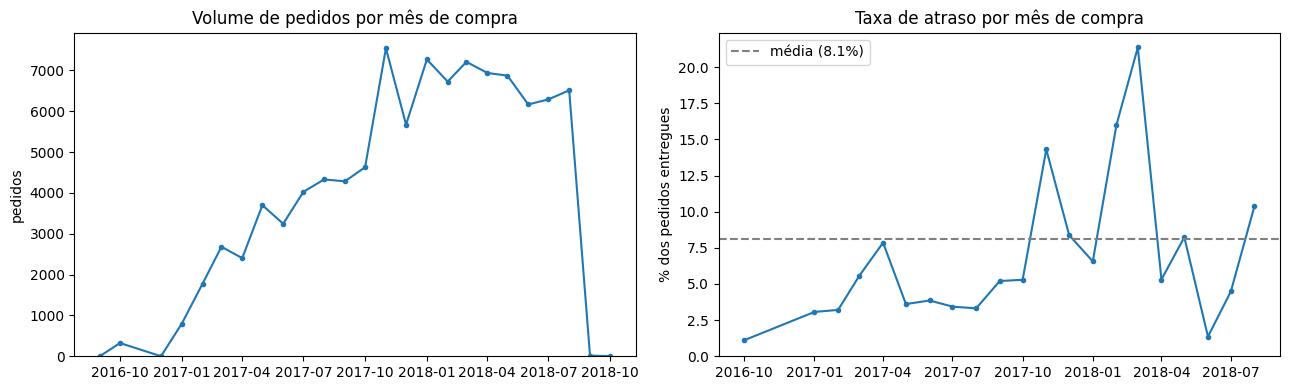

Período: Sep/2016 a Oct/2018 (25 meses)
Meses com menos de 100 pedidos (bordas pouco confiáveis):
ano_mes
2016-09-01     4
2016-12-01     1
2018-09-01    16
2018-10-01     4


In [13]:
# Pedidos por mês de compra.
serie = orders.groupby("ano_mes").size().sort_index()
serie.index = serie.index.to_timestamp()

# Taxa de atraso por mês, só com meses que têm pelo menos 100 pedidos entregues.
mensal = orders[orders["atrasado"].notna()].groupby("ano_mes").agg(
    pedidos=("order_id", "size"), taxa=("atrasado", "mean")
)
mensal = mensal[mensal["pedidos"] >= 100]
mensal.index = mensal.index.to_timestamp()
taxa = mensal["taxa"].astype(float) * 100
taxa_media = float(orders["atrasado"].mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(serie.index, serie.values, marker="o", markersize=3)
axes[0].set_title("Volume de pedidos por mês de compra")
axes[0].set_ylabel("pedidos")

axes[1].plot(taxa.index, taxa.values, marker="o", markersize=3)
axes[1].axhline(taxa_media, color="gray", linestyle="--", label=f"média ({taxa_media:.1f}%)")
axes[1].set_title("Taxa de atraso por mês de compra")
axes[1].set_ylabel("% dos pedidos entregues")
axes[1].legend()

for ax in axes:
    ax.set_ylim(0)

plt.tight_layout()
plt.show()

print(f"Período: {serie.index[0]:%b/%Y} a {serie.index[-1]:%b/%Y} ({len(serie)} meses)")
print("Meses com menos de 100 pedidos (bordas pouco confiáveis):")
print(serie[serie < 100].to_string())

> **Cuidado ao tratar isto como série temporal:** as pontas são artefato de coleta. Os
> primeiros meses têm volume irrisório e o último mês está incompleto. Para tendência ou
> sazonalidade, use só a janela com volume denso.

## 8. Resumo

In [14]:
status = orders["order_status"].value_counts()
status_pct = orders["order_status"].value_counts(normalize=True) * 100
entregues = orders[orders["order_status"] == "delivered"]

print("=" * 64)
print("RESUMO — olist_orders_dataset.csv")
print("=" * 64)
print(f"Pedidos                      : {len(orders)}")
print(f"Colunas                      : 8 originais + {orders.shape[1] - 8} derivadas")
print(f"Período de compra            : {orders['order_purchase_timestamp'].min():%d/%m/%Y} a {orders['order_purchase_timestamp'].max():%d/%m/%Y}")
print(f"Uma linha por pedido         : {'sim' if orders['order_id'].is_unique else 'NÃO (há duplicatas)'}")
print("-" * 64)
print(f"Entregues (delivered)        : {int(status['delivered'])} ({status_pct['delivered']:.2f}%)")
print(f"Cancelados                   : {int(status.get('canceled', 0))} ({status_pct.get('canceled', 0):.2f}%)")
print(f"Alertas do profiling         : {len(alertas)}")
print("-" * 64)
print(f"Entrega — mediana            : {entregues['d_entrega_total'].median():.1f} dias")
print(f"Entrega — média              : {entregues['d_entrega_total'].mean():.1f} dias")
print(f"Entrega — p95                : {entregues['d_entrega_total'].quantile(0.95):.1f} dias")
print(f"Aprovação — mediana          : {orders['h_aprovacao'].median():.1f} horas")
print(f"Prazo prometido — mediana    : {orders['d_prazo_prometido'].median():.1f} dias")
print(f"Folga sobre o prazo — mediana: {entregues['d_folga'].median():.1f} dias")
print(f"Taxa de atraso               : {taxa_media:.2f}%")
print(f"Linhas com inconsistência    : {int(relatorio['linhas'].sum())} (soma das checagens)")
print("=" * 64)
print("Relatórios HTML gerados em reports/:")
for caminho in sorted(REPORTS_DIR.glob("olist_orders_profiling*.html")):
    print(f"  · {caminho.name}  ({caminho.stat().st_size / 1024**2:.1f} MB)")

RESUMO — olist_orders_dataset.csv
Pedidos                      : 99441
Colunas                      : 8 originais + 9 derivadas
Período de compra            : 04/09/2016 a 17/10/2018
Uma linha por pedido         : sim
----------------------------------------------------------------
Entregues (delivered)        : 96478 (97.02%)
Cancelados                   : 625 (0.63%)
Alertas do profiling         : 5
----------------------------------------------------------------
Entrega — mediana            : 10.2 dias
Entrega — média              : 12.6 dias
Entrega — p95                : 29.3 dias
Aprovação — mediana          : 0.3 horas
Prazo prometido — mediana    : 23.2 dias
Folga sobre o prazo — mediana: 11.9 dias
Taxa de atraso               : 8.11%
Linhas com inconsistência    : 217 (soma das checagens)
Relatórios HTML gerados em reports/:
  · olist_orders_profiling.html  (1.6 MB)
  · olist_orders_profiling_comparativo.html  (0.8 MB)
  · olist_orders_profiling_enriquecido.html  (1.2 MB)


### Conclusões

1. **Granularidade:** 99.441 pedidos, uma linha por pedido (`order_id` único). O
   `customer_id` também é único, então esta tabela sozinha não identifica clientes recorrentes.
2. **Nulos estruturais:** só 0,62% das células estão vazias, todas em datas de aprovação,
   postagem e entrega de pedidos que não completaram o ciclo. Imputar média ou mediana nessas
   datas seria erro conceitual: ou se filtra a população, ou a ausência vira feature.
3. **Base desbalanceada:** `delivered` responde por 97% dos pedidos; cancelamento (0,63%) é
   classe rara.
4. **Atraso é minoria:** 8,11% dos pedidos entregues chegaram depois do prazo. A Olist promete
   prazos folgados (mediana de 23,2 dias para uma entrega mediana de 10,2 dias, folga mediana de
   11,9 dias).
5. **O que separa os atrasados:** no comparativo, a postagem demora mais (mediana de 3,4 contra
   2,1 dias) e a entrega total quase triplica (29,2 contra 9,7 dias), enquanto o prazo prometido
   é praticamente igual (22,2 contra 23,3 dias). O atraso nasce na logística depois da compra,
   não num prazo prometido mais curto.
6. **Inconsistências:** 217 marcações nas checagens de ordem das datas (0,2% da base), a maior
   parte postagem registrada antes da compra (166). São candidatas a regra de limpeza.
7. **Série temporal:** set/2016 a out/2018, com as pontas (meses com menos de 100 pedidos)
   pouco confiáveis para tendência ou sazonalidade.